# 04 · Modelo preditivo (opcional)

**Responsáveis:** todos (pipeline conduzido por P2)

**Pergunta que o modelo responde:** *considerando o que já aconteceu com o pedido (prazo, atraso, tentativas de entrega e atendimento), qual nota de NPS esse cliente deve dar e, portanto, quem precisa de uma ação antes da pesquisa?*

| | Arquivo |
|---|---|
| Entrada | `data/processed/nps_tratado.csv` (gerado pelo notebook 01) |
| Modelo salvo | `models/modelo_nps_ridge.joblib` |
| Figuras | `reports/figures/modelo_*.png` |

**Roteiro (itens exigidos no desafio):**
1. Definição da variável alvo
2. Seleção e preparação das variáveis de entrada
3. Lógica de separação dos dados (treino/teste)
4. Escolha do modelo
5. Forma de avaliação
6. Como a empresa usaria a solução na prática

> **Vazamento:** `csat_internal_score` e `repeat_purchase_30d` não entram como variáveis de entrada (seção 7.3 do README).

## 0. Configuração

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Caminhos relativos à raiz do repositório (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent
PROCESSED_PATH = ROOT / "data" / "processed" / "nps_tratado.csv"
FIGURES_DIR = ROOT / "reports" / "figures"
MODELS_DIR = ROOT / "models"

# Semente fixa: mesma divisão treino/teste e mesmos resultados em qualquer máquina
SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
# Mesmo estilo de gráfico do notebook 01
COR_SERIE = "#2a78d6"
COR_ALERTA = "#d64545"
COR_NEUTRA = "#c3c2b7"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SECUNDARIO = "#52514e"
COR_GRADE = "#e1e0d9"
COR_EIXO = "#c3c2b7"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_EIXO,
    "axes.labelcolor": COR_TEXTO_SECUNDARIO,
    "axes.titlecolor": COR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": COR_TEXTO_SECUNDARIO,
    "ytick.color": COR_TEXTO_SECUNDARIO,
    "font.size": 10,
})

## 1. Carga da base tratada

In [3]:
# Sempre partir da base tratada (gerada pelo notebook 01)
df = pd.read_csv(PROCESSED_PATH)
df["nps_category"] = pd.Categorical(
    df["nps_category"], categories=["Detrator", "Neutro", "Promotor"], ordered=True
)

print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas".replace(",", "."))
df["nps_category"].value_counts(normalize=True).mul(100).round(1).rename("% da base")

2.500 linhas x 25 colunas


nps_category
Detrator   84.40
Neutro     11.20
Promotor    4.40
Name: % da base, dtype: float64

## 2. Definição da target

O desafio sugere duas abordagens: **regressão** (estimar a nota de 0 a 10) ou **classificação** (satisfeito x insatisfeito). A escolha aqui é a **regressão sobre `nps_score`**, e a classificação entra só como comparação na seção 6.4.

**Por que regressão:**

- **A base é quase toda detratora.** 84% dos clientes têm nota abaixo de 7. Um classificador "detrator x não detrator" acertaria 84% dizendo "detrator" para todo mundo e não ajudaria a priorizar ninguém.
- **A nota mostra a gravidade.** Entre os detratores há quem deu 6,5 e quem deu 0. Para o negócio, esses clientes pedem ações diferentes (um pedido de desculpas x um contato ativo com compensação). A regressão preserva essa diferença; a classificação a esconde.
- **Uma nota prevista vira qualquer categoria depois.** Com a nota estimada é possível aplicar a mesma régua do projeto (detrator < 7 ≤ neutro < 9 ≤ promotor) ou criar faixas de risco próprias (seção 7), sem treinar um modelo novo.
- **É fácil de explicar.** "O modelo prevê nota 2,3 para esse cliente" é uma frase que qualquer gestor entende.

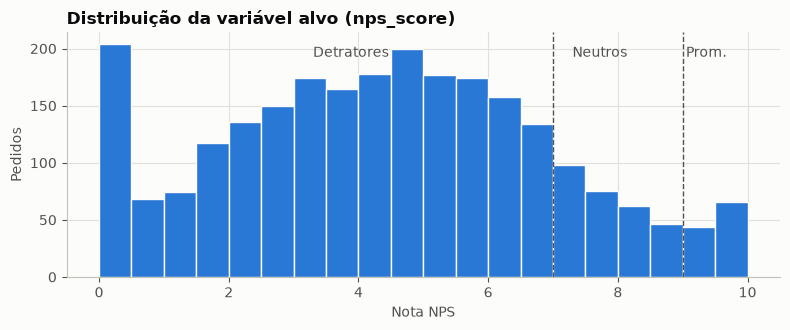

count   2500.00
mean       4.38
std        2.51
min        0.00
25%        2.60
50%        4.40
75%        6.10
max       10.00
Name: nps_score, dtype: float64

In [4]:
TARGET = "nps_score"

fig, eixo = plt.subplots(figsize=(8, 3.4))
eixo.hist(df[TARGET], bins=np.arange(0, 10.5, 0.5), color=COR_SERIE, edgecolor=COR_FUNDO)
for limite in (7, 9):
    eixo.axvline(limite, color=COR_TEXTO_SECUNDARIO, linestyle="--", linewidth=1)
eixo.set_title("Distribuição da variável alvo (nps_score)")
eixo.set_xlabel("Nota NPS")
eixo.set_ylabel("Pedidos")
eixo.text(3.3, eixo.get_ylim()[1] * 0.9, "Detratores", color=COR_TEXTO_SECUNDARIO)
eixo.text(7.3, eixo.get_ylim()[1] * 0.9, "Neutros", color=COR_TEXTO_SECUNDARIO)
eixo.text(9.05, eixo.get_ylim()[1] * 0.9, "Prom.", color=COR_TEXTO_SECUNDARIO)
fig.tight_layout()
plt.show()

df[TARGET].describe()

## 3. Seleção e preparação das variáveis

### 3.1 O que entra e o que fica de fora

A regra de seleção é **temporal**: só entra no modelo o que a empresa já sabe **antes** de enviar a pesquisa de NPS.

| Grupo | Variáveis | Decisão |
|---|---|---|
| Identificadores | `customer_id`, `order_id` | Fora: não descrevem a experiência |
| Vazamento | `csat_internal_score`, `repeat_purchase_30d` | Fora: são medidos junto ou depois do NPS (README 7.3) |
| Derivadas da target | `nps_category`, `is_detractor` | Fora: são a própria resposta |
| A confirmar | `complaints_count` | Fora no modelo final; testada à parte (3.2) |
| Derivadas de outras colunas | `total_delivery_days`, `is_late`, `flag_*` | Fora: repetem informação de colunas que já entram e criariam colinearidade no modelo linear |
| Cliente | `customer_age`, `customer_region`, `customer_tenure_months` | Entram |
| Pedido | `order_value`, `items_quantity`, `discount_value`, `payment_installments` | Entram |
| Logística | `delivery_time_days`, `delivery_delay_days`, `freight_value`, `delivery_attempts` | Entram |
| Atendimento | `customer_service_contacts`, `resolution_time_days` | Entram |

In [5]:
COLUNAS_ID = ["customer_id", "order_id"]
COLUNAS_VAZAMENTO = ["csat_internal_score", "repeat_purchase_30d"]
COLUNAS_DERIVADAS_TARGET = ["nps_category", "is_detractor"]
COLUNAS_A_CONFIRMAR = ["complaints_count"]

FEATURES_NUMERICAS = [
    # Cliente
    "customer_age", "customer_tenure_months",
    # Pedido
    "order_value", "items_quantity", "discount_value", "payment_installments",
    # Logística
    "delivery_time_days", "delivery_delay_days", "freight_value", "delivery_attempts",
    # Atendimento
    "customer_service_contacts", "resolution_time_days",
]
FEATURES_CATEGORICAS = ["customer_region"]

# Trava de segurança: nenhuma coluna proibida pode estar na lista de entrada
proibidas = set(COLUNAS_ID + COLUNAS_VAZAMENTO + COLUNAS_DERIVADAS_TARGET + [TARGET])
assert proibidas.isdisjoint(FEATURES_NUMERICAS + FEATURES_CATEGORICAS), "Vazamento nas features!"

print(f"{len(FEATURES_NUMERICAS)} numéricas + {len(FEATURES_CATEGORICAS)} categórica")

12 numéricas + 1 categórica


### 3.2 `complaints_count`: entra ou não?

O README deixa `complaints_count` como **a confirmar**: se a reclamação é registrada durante a jornada (ex.: o cliente reclama do atraso), ela pode entrar; se for registrada junto com a pesquisa, é vazamento.

Para o grupo decidir com números, o modelo é avaliado **com e sem** a variável na seção 4. Enquanto não houver confirmação, a versão final fica **sem** ela, que é a opção segura. A constante abaixo permite trocar a decisão em um único lugar.

In [6]:
# Trocar para True só se o grupo confirmar que a reclamação é registrada ANTES da pesquisa
INCLUIR_COMPLAINTS = False

features_numericas_final = FEATURES_NUMERICAS + (["complaints_count"] if INCLUIR_COMPLAINTS else [])
features_final = features_numericas_final + FEATURES_CATEGORICAS
features_final

['customer_age',
 'customer_tenure_months',
 'order_value',
 'items_quantity',
 'discount_value',
 'payment_installments',
 'delivery_time_days',
 'delivery_delay_days',
 'freight_value',
 'delivery_attempts',
 'customer_service_contacts',
 'resolution_time_days',
 'customer_region']

### 3.3 Preparação

O pré-processamento fica **dentro de um `Pipeline`** do scikit-learn, para que seja aprendido só com os dados de treino (sem vazar média e desvio do teste) e para que o mesmo tratamento seja aplicado automaticamente quando o modelo for usado em pedidos novos.

- **Numéricas:** padronização (`StandardScaler`, média 0 e desvio 1). Necessária para o Ridge, que penaliza coeficientes e seria injusto com variáveis em escalas diferentes (R$ x dias). Os outliers foram mantidos no notebook 01 e a padronização não os remove.
- **Região:** *one-hot encoding*, com uma coluna 0/1 por região. `handle_unknown="ignore"` evita erro se surgir uma região nova em produção.
- Não há nulos para imputar (notebook 01).

In [7]:
def criar_preprocessador(features_numericas):
    """Padroniza as numéricas e transforma a região em colunas 0/1."""
    return ColumnTransformer([
        ("numericas", StandardScaler(), features_numericas),
        ("regiao", OneHotEncoder(handle_unknown="ignore"), FEATURES_CATEGORICAS),
    ])

## 4. Separação treino/teste

- **80% treino / 20% teste**, com `random_state` fixo para reprodutibilidade.
- **Estratificada por `nps_category`**: como só 4% são promotores, uma divisão puramente aleatória poderia deixar o teste com pouquíssimos promotores. A estratificação mantém a mesma proporção de detratores, neutros e promotores nos dois conjuntos.
- **O teste é usado uma única vez**, no fim (seção 6). A comparação de modelos é feita com **validação cruzada de 5 dobras dentro do treino**.

> **Por que não uma divisão por data?** Em produção, o ideal é treinar com meses passados e testar no mês seguinte, simulando o uso real. A base não tem data do pedido, então a divisão aleatória estratificada é a melhor opção disponível. Isso está nas limitações (seção 8).

In [8]:
X = df[FEATURES_NUMERICAS + COLUNAS_A_CONFIRMAR + FEATURES_CATEGORICAS]
y = df[TARGET]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=df["nps_category"]
)

resumo_divisao = pd.DataFrame({
    "pedidos": [len(X_treino), len(X_teste)],
    "nota média": [y_treino.mean(), y_teste.mean()],
    "% detratores": [(y_treino < 7).mean() * 100, (y_teste < 7).mean() * 100],
}, index=["treino", "teste"])
resumo_divisao

,pedidos,nota média,% detratores
treino,2000,4.41,84.35
teste,500,4.24,84.40


## 5. Escolha do modelo

Quatro candidatos, do mais simples ao mais flexível, todos com o mesmo pré-processamento:

| Modelo | Ideia | Ponto forte | Ponto fraco |
|---|---|---|---|
| **Baseline** (média) | Prevê a mesma nota média para todos | Referência mínima: qualquer modelo tem que superá-lo | Não usa nenhuma informação |
| **Ridge** | Regressão linear com penalização leve | Coeficientes fáceis de explicar ("cada dia de atraso tira X pontos") | Só capta efeitos lineares |
| **Random Forest** | Média de várias árvores de decisão | Capta efeitos não lineares e interações | Mais difícil de explicar |
| **Gradient Boosting** | Árvores em sequência, cada uma corrigindo a anterior | Costuma ter o melhor desempenho em dados tabulares | Mais difícil de explicar e de ajustar |

A métrica de comparação é o **MAE** (erro absoluto médio): "em média, o modelo erra a nota em X pontos". O R² complementa, indicando quanto da variação das notas o modelo explica.

In [9]:
CANDIDATOS = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED
    ),
}
validacao = KFold(n_splits=5, shuffle=True, random_state=SEED)


def avaliar_candidatos(features_numericas):
    """Validação cruzada de 5 dobras no treino para cada candidato."""
    linhas = []
    for nome, estimador in CANDIDATOS.items():
        pipeline = Pipeline([
            ("preparacao", criar_preprocessador(features_numericas)),
            ("modelo", estimador),
        ])
        resultado = cross_validate(
            pipeline, X_treino, y_treino, cv=validacao,
            scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
        )
        linhas.append({
            "modelo": nome,
            "MAE": -resultado["test_neg_mean_absolute_error"].mean(),
            "RMSE": -resultado["test_neg_root_mean_squared_error"].mean(),
            "R²": resultado["test_r2"].mean(),
            "MAE (desvio entre dobras)": resultado["test_neg_mean_absolute_error"].std(),
        })
    return pd.DataFrame(linhas).set_index("modelo").sort_values("MAE")


comparacao_sem = avaliar_candidatos(FEATURES_NUMERICAS)
comparacao_com = avaliar_candidatos(FEATURES_NUMERICAS + ["complaints_count"])

comparacao = pd.concat(
    {"sem complaints_count": comparacao_sem, "com complaints_count": comparacao_com}, axis=1
)
comparacao

sem complaints_count                                       \
                                   MAE RMSE    R² MAE (desvio entre dobras)   
modelo                                                                        
Ridge                             1.36 1.70  0.54                      0.03   
Gradient Boosting                 1.40 1.75  0.51                      0.03   
Random Forest                     1.42 1.75  0.51                      0.02   
Baseline (média)                  2.04 2.50 -0.00                      0.03   

                  com complaints_count                                       
                                   MAE RMSE    R² MAE (desvio entre dobras)  
modelo                                                                       
Ridge                             1.31 1.65  0.56                      0.03  
Gradient Boosting                 1.34 1.69  0.54                      0.01  
Random Forest                     1.36 1.70  0.54                      0.02  
Baseline (média)                  2.04 2.50 -0.00                      0.03

**Leitura da comparação:**

- **Todos os modelos superam muito o baseline**: o erro médio cai de cerca de 2 pontos para cerca de 1,3 a 1,4 ponto, e os modelos explicam cerca de metade da variação das notas.
- **O Ridge (linear) empata ou vence os modelos de árvore.** Isso indica que as relações na base são, em grande parte, lineares: cada dia de atraso ou contato a mais derruba a nota em uma quantidade parecida. Modelos mais complexos não trazem ganho.
- **`complaints_count` melhora pouco** (o MAE cai cerca de 0,05 ponto). Ou seja, deixá-la de fora enquanto a dúvida sobre o momento do registro não é resolvida custa pouco.

**Modelo escolhido: Ridge.** Desempenho igual ou melhor que as alternativas, treino instantâneo e, principalmente, **explicável**: cada coeficiente vira uma frase de negócio. Pelo princípio da parcimônia, entre modelos equivalentes fica o mais simples.

In [10]:
modelo_final = Pipeline([
    ("preparacao", criar_preprocessador(features_numericas_final)),
    ("modelo", Ridge(alpha=1.0)),
])
modelo_final.fit(X_treino[features_final], y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['customer_age','customer_tenure_months','order_value',..., 'customer_service_contacts','resolution_time_days','customer_region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('regiao', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto 

## 6. Avaliação

A partir daqui o conjunto de **teste** (20% que o modelo nunca viu) é usado pela primeira e única vez.

### 6.1 Métricas de erro

In [11]:
previsao_teste = np.clip(modelo_final.predict(X_teste[features_final]), 0, 10)  # nota só existe entre 0 e 10
previsao_baseline = np.full(len(y_teste), y_treino.mean())

metricas_teste = pd.DataFrame({
    "MAE": [mean_absolute_error(y_teste, previsao_baseline), mean_absolute_error(y_teste, previsao_teste)],
    "RMSE": [root_mean_squared_error(y_teste, previsao_baseline), root_mean_squared_error(y_teste, previsao_teste)],
    "R²": [r2_score(y_teste, previsao_baseline), r2_score(y_teste, previsao_teste)],
}, index=["Baseline (média)", "Ridge (modelo final)"])

reducao_erro = 1 - metricas_teste.loc["Ridge (modelo final)", "MAE"] / metricas_teste.loc["Baseline (média)", "MAE"]
print(f"O modelo reduz o erro médio em {reducao_erro:.0%} em relação a 'chutar a média'.")
metricas_teste

O modelo reduz o erro médio em 32% em relação a 'chutar a média'.


,MAE,RMSE,R²
Baseline (média),2.11,2.55,-0.00
Ridge (modelo final),1.44,1.83,0.48


**Em linguagem de negócio:** o modelo erra a nota, em média, em cerca de 1,4 ponto na escala de 0 a 10, contra 2,1 pontos de quem só "chuta a média". Não é uma previsão exata da nota de cada cliente, mas é suficiente para **separar quem vai dar 1 de quem vai dar 7**, que é o que importa para priorizar ações.

O resultado no teste é um pouco pior que o da validação cruzada (MAE 1,44 x 1,36; R² 0,48 x 0,54), uma variação normal para uma amostra de 500 pedidos. Não há sinal de que o modelo esteja decorando o treino (*overfitting*): um modelo linear com 13 variáveis e 2.000 exemplos tem pouca margem para isso.

### 6.2 Nota real x nota prevista

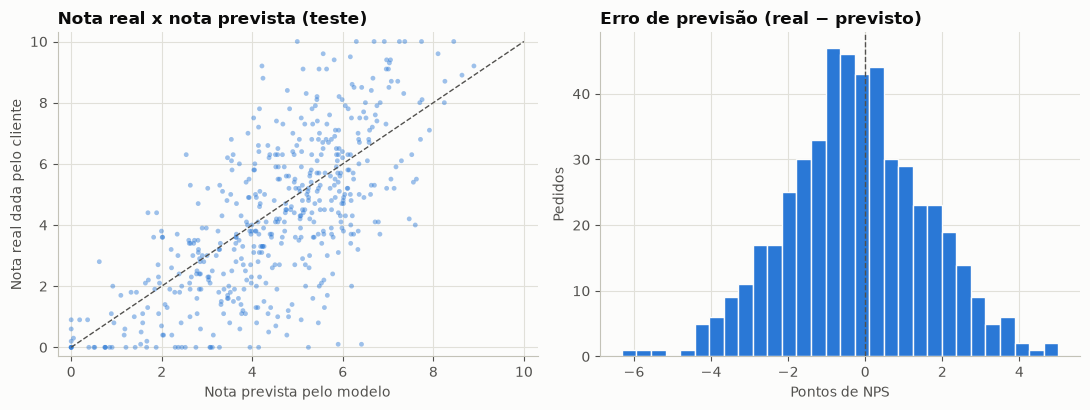

Pedidos com erro de até 1 ponto: 45%
Pedidos com erro de até 2 pontos: 73%


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))

eixo = eixos[0]
eixo.scatter(previsao_teste, y_teste, s=12, alpha=0.45, color=COR_SERIE, edgecolor="none")
eixo.plot([0, 10], [0, 10], color=COR_TEXTO_SECUNDARIO, linestyle="--", linewidth=1)
eixo.set_xlim(-0.3, 10.3)
eixo.set_ylim(-0.3, 10.3)
eixo.set_title("Nota real x nota prevista (teste)")
eixo.set_xlabel("Nota prevista pelo modelo")
eixo.set_ylabel("Nota real dada pelo cliente")

eixo = eixos[1]
erros = y_teste - previsao_teste
eixo.hist(erros, bins=30, color=COR_SERIE, edgecolor=COR_FUNDO)
eixo.axvline(0, color=COR_TEXTO_SECUNDARIO, linestyle="--", linewidth=1)
eixo.set_title("Erro de previsão (real − previsto)")
eixo.set_xlabel("Pontos de NPS")
eixo.set_ylabel("Pedidos")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "modelo_real_vs_previsto.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Pedidos com erro de até 1 ponto: {(erros.abs() <= 1).mean():.0%}")
print(f"Pedidos com erro de até 2 pontos: {(erros.abs() <= 2).mean():.0%}")

Os pontos acompanham a diagonal (previsão = realidade). O erro é simétrico e centrado em zero: o modelo não tem tendência de superestimar nem de subestimar as notas.

### 6.3 O que mais pesa na nota prevista

Duas leituras complementares:

1. **Coeficientes do Ridge convertidos para a unidade original:** quantos pontos de NPS a nota prevista muda para cada unidade a mais da variável (ex.: +1 dia de atraso), mantendo o resto igual.
2. **Importância por permutação** (no teste): quanto o erro do modelo piora quando os valores de uma variável são embaralhados. Quanto mais o erro sobe, mais o modelo depende dela.

In [13]:
NOMES_AMIGAVEIS = {
    "customer_age": "Idade do cliente (anos)",
    "customer_tenure_months": "Tempo de relacionamento (meses)",
    "order_value": "Valor do pedido (R$)",
    "items_quantity": "Itens no pedido",
    "discount_value": "Desconto (R$)",
    "payment_installments": "Parcelas",
    "delivery_time_days": "Prazo de entrega previsto (dias)",
    "delivery_delay_days": "Dias de atraso",
    "freight_value": "Frete (R$)",
    "delivery_attempts": "Tentativas de entrega",
    "customer_service_contacts": "Contatos com o atendimento",
    "resolution_time_days": "Tempo de resolução (dias)",
    "complaints_count": "Reclamações",
    "customer_region": "Região",
}

# Coeficiente padronizado / desvio padrão = efeito por unidade original da variável
escalador = modelo_final.named_steps["preparacao"].named_transformers_["numericas"]
coeficientes = modelo_final.named_steps["modelo"].coef_[: len(features_numericas_final)]
efeito_por_unidade = pd.Series(coeficientes / escalador.scale_, index=features_numericas_final)

efeitos = pd.DataFrame({
    "variável": [NOMES_AMIGAVEIS[c] for c in efeito_por_unidade.index],
    "pontos de NPS por +1 unidade": efeito_por_unidade.values,
}).set_index("variável").sort_values("pontos de NPS por +1 unidade")
efeitos

,pontos de NPS por +1 unidade
variável,
Dias de atraso,-1.03
Contatos com o atendimento,-0.77
Tempo de resolução (dias),-0.14
Frete (R$),-0.01
Tempo de relacionamento (meses),-0.00
Desconto (R$),-0.00
Prazo de entrega previsto (dias),0.00
Itens no pedido,0.00
Valor do pedido (R$),0.00


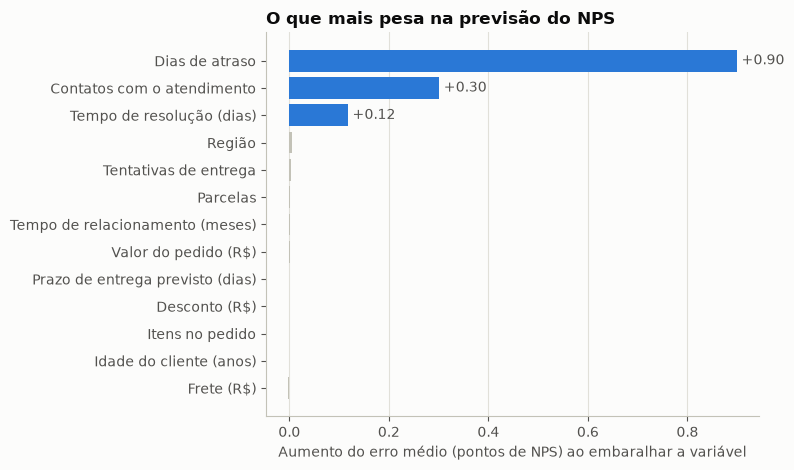

In [14]:
importancia = permutation_importance(
    modelo_final, X_teste[features_final], y_teste,
    scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEED,
)
importancia = pd.Series(importancia.importances_mean, index=features_final).sort_values()
importancia.index = [NOMES_AMIGAVEIS[c] for c in importancia.index]

fig, eixo = plt.subplots(figsize=(8, 4.8))
cores = [COR_SERIE if valor >= 0.05 else COR_NEUTRA for valor in importancia]
eixo.barh(importancia.index, importancia.values, color=cores)
eixo.set_title("O que mais pesa na previsão do NPS")
eixo.set_xlabel("Aumento do erro médio (pontos de NPS) ao embaralhar a variável")
eixo.grid(axis="y", visible=False)
for posicao, valor in enumerate(importancia.values):
    if valor >= 0.05:
        eixo.text(valor + 0.01, posicao, f"+{valor:.2f}", va="center", color=COR_TEXTO_SECUNDARIO)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "modelo_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura para o gestor:**

- **Atraso na entrega é, de longe, o fator mais forte.** Cada dia de atraso tira cerca de 1 ponto da nota prevista. Um pedido com 4 dias de atraso já começa uns 4 pontos abaixo de um pedido entregue no prazo.
- **Atendimento vem em seguida.** Cada contato a mais com o atendimento tira quase 0,8 ponto, e cada dia a mais para resolver o problema tira cerca de 0,15 ponto.
- **Tentativas de entrega, sozinhas, não pesam.** Considerando o atraso, uma tentativa a mais não muda a nota. O que incomoda o cliente é o pedido chegar tarde, não quantas vezes o entregador passou.
- **Perfil do cliente e do pedido quase não importam.** Idade, região, tempo de casa, valor, desconto, parcelas e frete têm efeito próximo de zero. A satisfação é decidida pela **operação** (entrega e atendimento), não por *quem* é o cliente ou *quanto* ele gastou.

Isso confirma os achados da EDA e é uma mensagem forte para os slides: **para melhorar o NPS, o caminho é cumprir o prazo e resolver rápido, não dar desconto.**

> Os coeficientes mostram **associação**, não causa comprovada. Ver limitações (seção 8).

### 6.4 Comparação: e se fosse classificação?

Para responder à sugestão do desafio, um classificador (**regressão logística**, com pesos balanceados por causa dos 84% de detratores) foi treinado para prever diretamente "detrator x não detrator". Ele é comparado com o modelo de regressão, transformando a nota prevista em categoria pela regra do projeto (nota prevista < 7 = detrator).

In [15]:
eh_detrator_treino = (y_treino < 7).astype(int)
eh_detrator_teste = (y_teste < 7).astype(int)

classificador = Pipeline([
    ("preparacao", criar_preprocessador(features_numericas_final)),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
classificador.fit(X_treino[features_final], eh_detrator_treino)
probabilidade_detrator = classificador.predict_proba(X_teste[features_final])[:, 1]

# AUC: a chance de o modelo dar risco maior a um detrator do que a um não detrator.
# Para a regressão, quanto MENOR a nota prevista, maior o risco, por isso o sinal negativo.
auc = pd.Series({
    "Regressão (Ridge), nota prevista": roc_auc_score(eh_detrator_teste, -previsao_teste),
    "Classificação (logística)": roc_auc_score(eh_detrator_teste, probabilidade_detrator),
}, name="AUC no teste")
auc.to_frame()

,AUC no teste
"Regressão (Ridge), nota prevista",0.85
Classificação (logística),0.84


In [16]:
detrator_previsto = (previsao_teste < 7).astype(int)
print("Regressão convertida em categoria (nota prevista < 7 = detrator):\n")
print(classification_report(
    eh_detrator_teste, detrator_previsto, target_names=["não detrator", "detrator"], digits=2
))

pd.DataFrame(
    confusion_matrix(eh_detrator_teste, detrator_previsto),
    index=["real: não detrator", "real: detrator"],
    columns=["previsto: não detrator", "previsto: detrator"],
)

Regressão convertida em categoria (nota prevista < 7 = detrator):

              precision    recall  f1-score   support

não detrator       0.66      0.24      0.36        78
    detrator       0.87      0.98      0.92       422

    accuracy                           0.86       500
   macro avg       0.76      0.61      0.64       500
weighted avg       0.84      0.86      0.83       500



,previsto: não detrator,previsto: detrator
real: não detrator,19,59
real: detrator,10,412


**Conclusão da comparação:** os dois enfoques têm poder de separação parecido (AUC próxima). A regressão foi mantida porque, **com a mesma qualidade**, ela entrega mais: além de dizer *se* o cliente tende a ser detrator, diz *o quão insatisfeito* ele deve estar, o que permite as faixas de prioridade da próxima seção.

## 7. Uso do modelo no negócio

### 7.1 Faixas de risco

A nota prevista vira uma **régua de prioridade** para a área de Experiência do Cliente:

| Faixa | Nota prevista | Ação sugerida |
|---|---|---|
| **Crítico** | abaixo de 3 | Contato ativo do atendimento em até 24 h, com compensação (frete grátis ou cupom na próxima compra) |
| **Alto** | 3 a 5 | Mensagem proativa de desculpas e atualização do status do pedido |
| **Moderado** | 5 a 7 | Monitorar; acionar se surgir novo atraso ou contato |
| **Baixo** | 7 ou mais | Nenhuma ação; candidato a convite de avaliação pública ou programa de indicação |

Os cortes são um ponto de partida e devem ser calibrados pelo custo da ação x valor do cliente (risco 4 da questão 2.4).

In [17]:
FAIXAS_RISCO = [-np.inf, 3, 5, 7, np.inf]
NOMES_FAIXAS = ["Crítico (<3)", "Alto (3–5)", "Moderado (5–7)", "Baixo (≥7)"]

resultado_teste = pd.DataFrame({"nota_real": y_teste, "nota_prevista": previsao_teste})
resultado_teste["faixa_risco"] = pd.cut(
    resultado_teste["nota_prevista"], bins=FAIXAS_RISCO, labels=NOMES_FAIXAS, right=False
)

tabela_faixas = resultado_teste.groupby("faixa_risco", observed=False).agg(
    pedidos=("nota_real", "size"),
    nota_real_media=("nota_real", "mean"),
    pct_detratores=("nota_real", lambda notas: (notas < 7).mean() * 100),
    pct_nota_abaixo_de_3=("nota_real", lambda notas: (notas < 3).mean() * 100),
)
tabela_faixas["% dos pedidos"] = tabela_faixas["pedidos"] / tabela_faixas["pedidos"].sum() * 100
tabela_faixas

,pedidos,nota_real_media,pct_detratores,pct_nota_abaixo_de_3,% dos pedidos
faixa_risco,,,,,
Crítico (<3),103,1.72,100.00,76.70,20.60
Alto (3–5),180,3.78,93.33,35.56,36.00
Moderado (5–7),188,5.53,75.00,9.04,37.60
Baixo (≥7),29,7.74,34.48,0.00,5.80


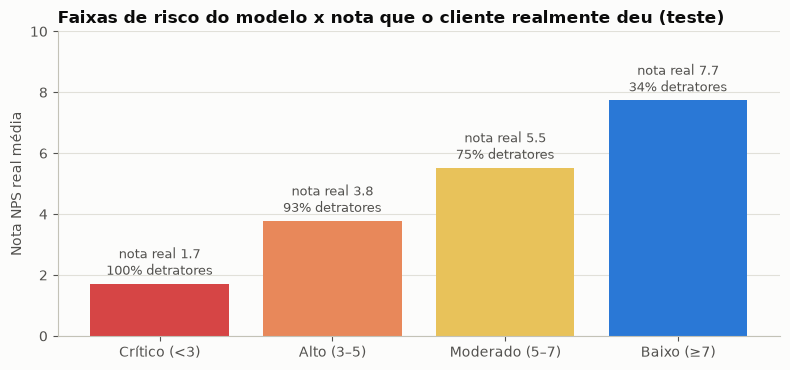

In [18]:
fig, eixo = plt.subplots(figsize=(8, 3.8))
cores_faixas = [COR_ALERTA, "#e8885a", "#e8c25a", COR_SERIE]
barras = eixo.bar(tabela_faixas.index.astype(str), tabela_faixas["nota_real_media"], color=cores_faixas)
for barra, (_, linha) in zip(barras, tabela_faixas.iterrows()):
    eixo.text(
        barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.15,
        f"nota real {linha['nota_real_media']:.1f}\n{linha['pct_detratores']:.0f}% detratores",
        ha="center", va="bottom", fontsize=9, color=COR_TEXTO_SECUNDARIO,
    )
eixo.set_ylim(0, 10)
eixo.set_title("Faixas de risco do modelo x nota que o cliente realmente deu (teste)")
eixo.set_ylabel("Nota NPS real média")
eixo.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "modelo_faixas_risco.png", dpi=150, bbox_inches="tight")
plt.show()

As faixas **separam bem os clientes na vida real**: a nota real média sobe faixa a faixa (de 1,7 no "Crítico" para 7,7 no "Baixo"). Na faixa "Crítico", 100% dos clientes viraram detratores e três em cada quatro deram nota abaixo de 3. Ou seja, se o time só tiver braço para atender um quinto dos pedidos, o modelo diz exatamente quais são.

### 7.2 Como a solução funcionaria no dia a dia

1. **Quando rodar:** o modelo é aplicado **diariamente a todos os pedidos em andamento ou recém-entregues que ainda não receberam a pesquisa**. A nota prevista é atualizada a cada novo evento: um dia a mais de atraso, uma tentativa de entrega frustrada, um novo contato com o atendimento.
2. **De onde vêm os dados:** exatamente das mesmas colunas usadas aqui (sistema de pedidos, transportadora e CRM de atendimento). Nada depende da pesquisa.
3. **Quem recebe:** a lista ordenada por faixa de risco vai para o time de Experiência do Cliente (fila de contatos proativos) e, de forma agregada, para logística (quais transportadoras/regiões concentram pedidos críticos).
4. **Como medir o retorno:** separar aleatoriamente uma parte dos clientes "Críticos" que **não** recebe ação (grupo de controle) e comparar o NPS real e a recompra dos dois grupos. Assim a empresa sabe se as ações funcionam de verdade, e não só que o modelo acerta.
5. **Manutenção:** acompanhar mensalmente o MAE com as notas reais que chegarem e retreinar quando o erro subir, por exemplo após mudança de transportadora ou de política de atendimento.

### 7.3 Simulação: quanto vale reduzir o atraso?

Exercício de "e se" com o modelo: se os atrasos dos pedidos de teste fossem limitados a no máximo N dias, quanto subiria a nota média prevista?

In [19]:
cenarios = {}
for atraso_maximo in [None, 3, 2, 1, 0]:
    X_cenario = X_teste[features_final].copy()
    if atraso_maximo is not None:
        X_cenario["delivery_delay_days"] = X_cenario["delivery_delay_days"].clip(upper=atraso_maximo)
    notas_cenario = np.clip(modelo_final.predict(X_cenario), 0, 10)
    nome = "Situação atual (previsto)" if atraso_maximo is None else f"Atraso limitado a {atraso_maximo} dia(s)"
    cenarios[nome] = notas_cenario.mean()

tabela_cenarios = pd.Series(cenarios, name="nota média prevista").to_frame()
tabela_cenarios["ganho x situação atual"] = tabela_cenarios["nota média prevista"] - tabela_cenarios.iloc[0, 0]
tabela_cenarios

,nota média prevista,ganho x situação atual
Situação atual (previsto),4.47,0.00
Atraso limitado a 3 dia(s),4.76,0.28
Atraso limitado a 2 dia(s),5.19,0.72
Atraso limitado a 1 dia(s),5.87,1.40
Atraso limitado a 0 dia(s),6.78,2.31


Eliminar os atrasos elevaria a nota média prevista em mais de 2 pontos (de cerca de 4,5 para 6,8), e só cortar os atrasos acima de 1 dia já rende cerca de 1,4 ponto. É um argumento quantitativo para priorizar o **SLA logístico** e para renegociar contratos com transportadoras.

> A comparação usa a **nota média**, e não a % de detratores prevista, porque modelos de regressão "puxam" as previsões para perto da média: a contagem de detratores previstos sairia distorcida.

> **Cuidado:** a simulação assume que o efeito do atraso é causal e que o resto da experiência ficaria igual. Ela serve para **dimensionar ordem de grandeza e priorizar**, não como promessa de resultado.

### 7.4 Salvando o modelo

In [20]:
MODELS_DIR.mkdir(exist_ok=True)
caminho_modelo = MODELS_DIR / "modelo_nps_ridge.joblib"

# Salva o pipeline completo (preparação + modelo) e a lista de colunas esperadas
joblib.dump({"pipeline": modelo_final, "features": features_final}, caminho_modelo)
print("Modelo salvo em", caminho_modelo.relative_to(ROOT))

Modelo salvo em models\modelo_nps_ridge.joblib


In [21]:
# Exemplo de uso: carregar o modelo e pontuar pedidos "novos"
artefato = joblib.load(caminho_modelo)
pedidos_novos = X_teste[artefato["features"]].head(5)

notas = np.clip(artefato["pipeline"].predict(pedidos_novos), 0, 10)
pedidos_novos.assign(
    nota_prevista=notas.round(1),
    faixa_risco=pd.cut(notas, bins=FAIXAS_RISCO, labels=NOMES_FAIXAS, right=False),
)[["delivery_delay_days", "delivery_attempts", "customer_service_contacts",
   "resolution_time_days", "nota_prevista", "faixa_risco"]]

,delivery_delay_days,delivery_attempts,customer_service_contacts,resolution_time_days,nota_prevista,faixa_risco
1648,2,3,1,2,5.60,Moderado (5–7)
169,0,3,4,1,5.50,Moderado (5–7)
2269,0,3,2,10,5.80,Moderado (5–7)
1273,2,3,2,8,4.20,Alto (3–5)
1492,3,2,2,7,3.00,Alto (3–5)


## 8. Limitações e riscos

- **Associação não é causa.** O modelo mostra que atraso e contatos andam junto com notas baixas. É muito provável que haja causa, mas a prova vem do teste com grupo de controle (7.2).
- **Cerca de metade da variação é explicada.** A outra parte depende de coisas que a base não tem: qualidade do produto, avaria, expectativa do cliente, humor no dia. O modelo serve para **priorizar grupos**, não para cravar a nota de um cliente.
- **Sem data na base.** A divisão treino/teste é aleatória; em produção o modelo deve ser validado em meses futuros.
- **Base sintética e muito detratora (NPS −80).** Os pesos podem mudar em uma operação com perfil diferente; retreinar com dados reais antes de usar.
- **`complaints_count` pendente.** Se for confirmado que a reclamação é registrada antes da pesquisa, basta trocar `INCLUIR_COMPLAINTS = True` e reexecutar (ganho pequeno de precisão).
- **Viés de seleção.** O modelo aprende só com quem respondeu à pesquisa (questão 2.4). Clientes que não respondem podem se comportar diferente.
- **Uso ético.** A nota prevista deve orientar **cuidado extra** com o cliente, nunca reduzir atendimento ou benefícios de quem tem nota prevista baixa.